# Credit Card Fraud Detection Project
Building a machine learning model to flag fraudulent credit card transactions. This project is a case study in handling extreme class imbalance and choosing the right evaluation metrics.

## Overview
Fraud is rare but expensive: in this dataset, only
0.17% of transactions are fraudulent. The detector will be judged on precision and recall rather than misleading accuracy.

## Dataset
Kaggle, Credit Card Fraud Detection: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud We have 492 frauds out of 284,807 transactions. Features V1 to V28, 'Time', and 'Amount' are all used for training the model.

## Approach
1. Explore the data and quantify the class imbalance
2. Split the data 60/20/20 into train, validation and test sets (stratified), scale features, and apply class weighting
3. Compare Logistic Regression, Random Forest, and XGBoost on the validation set
4. Tune the decision threshold on the validation set using a precision/recall curve
5. Evaluate the final model once on the untouched test set

## Result
Final model: XGBoost at the default 0.5 threshold. On the held-out test set it catches 83% of fraud at 89% precision, with only 10 false alarms across roughly 57,000 transactions. Lowering the threshold added many false alarms for very little extra recall, so the default was kept.

```
Author: Arda Duman
Date created: May 23, 2026
Last updated: October 12, 2026
```







In [12]:
# === Imports ===
import pandas as pd
import matplotlib.pyplot as plt

# Load the data (downloads the dataset from Kaggle automatically)
import os
import kagglehub

# Models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Evaluation metrics
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    precision_score,
    recall_score,
)

In [13]:
# Load the data

path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
df = pd.read_csv(os.path.join(path, "creditcard.csv"))  # csv-to-DataFrame

print(df.shape)  # (284807, 31)
df.head()

Using Colab cache for faster access to the 'creditcardfraud' dataset.
(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [14]:
# Inspect the data

print(df['Class'].value_counts()) # number of legitimate and fraudulent transactions
print()
print(df['Class'].value_counts(normalize=True) * 100) # see the proportions

Class
0    284315
1       492
Name: count, dtype: int64

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


In [15]:
# Separate features (X) from the target label (Y)

X = df.drop('Class', axis=1) # we remove the answers to train the model
Y = df['Class'] # we keep the answers here

print(X.shape )
print(Y.shape)

(284807, 30)
(284807,)


In [16]:
# Split into train (60%), validation (20%) and test (20%), stratified to preserve the fraud ratio
# The validation set is used to compare models and tune the threshold; the test set is only used once at the end

X_temp, X_test, Y_temp, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42, stratify=Y
)
X_train, X_val, Y_train, Y_val = train_test_split(
    X_temp, Y_temp, test_size=0.25, random_state=42, stratify=Y_temp  # 0.25 of 80% = 20%
)

print(X_train.shape, X_val.shape, X_test.shape)

(170883, 30) (56962, 30) (56962, 30)


In [17]:
# Scale features - fit on train only to avoid leaking validation/test info - this prevents big numbers from overshadowing smaller numbers

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [18]:
# Train a logistic regression model

# learning and testing logistic regression algorithm

lr_model = LogisticRegression(max_iter=1000, class_weight='balanced')

lr_model.fit(X_train_scaled, Y_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

In [19]:
# Train a Random Forest (an ensemble of voting decision trees)

rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
)
rf_model.fit(X_train_scaled, Y_train)

RandomForestClassifier(class_weight='balanced', n_jobs=-1, random_state=42)

In [20]:
# Train an XGBoost model - after testing, this algorithm had the best results (recall and precision)

spw = (Y_train == 0).sum() / (Y_train == 1).sum()   # ~577: legit-to-fraud ratio

xgb_model = XGBClassifier(
    n_estimators=300,
    scale_pos_weight=spw,
    random_state=42,
    n_jobs=-1,
    eval_metric="logloss"
)
xgb_model.fit(X_train_scaled, Y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=-1,
              num_parallel_tree=None, ...)

In [21]:
# Compare the three models on the validation set (default 0.5 threshold)

for name, m in [("Logistic Regression", lr_model),
                ("Random Forest", rf_model),
                ("XGBoost", xgb_model)]:
    pred = m.predict(X_val_scaled)
    prec = precision_score(Y_val, pred)
    rec = recall_score(Y_val, pred)
    fp = confusion_matrix(Y_val, pred)[0, 1]
    print(f"{name:20s} precision {prec:.0%}  recall {rec:.0%}  false alarms {fp}")

Logistic Regression  precision 6%  recall 90%  false alarms 1403
Random Forest        precision 96%  recall 71%  false alarms 3
XGBoost              precision 92%  recall 78%  false alarms 7


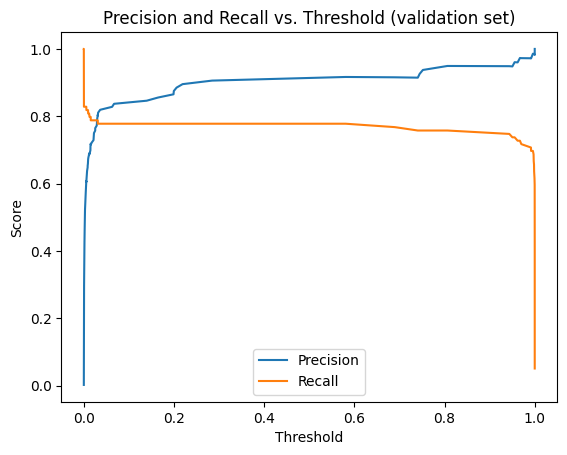

In [23]:
# Get the model's fraud-probability score for each validation transaction
Y_val_scores = xgb_model.predict_proba(X_val_scaled)[:, 1]

# Precision and recall at every possible threshold (validation set)
precisions, recalls, thresholds = precision_recall_curve(Y_val, Y_val_scores)

# Plot precision and recall as the threshold changes
plt.plot(thresholds, precisions[:-1], label="Precision")
plt.plot(thresholds, recalls[:-1], label="Recall")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall vs. Threshold (validation set)")
plt.legend()
plt.show()

In [26]:
# Compare the tradeoff at several thresholds (validation set)

for t in [0.5, 0.3, 0.1, 0.05, 0.02, 0.01, 0.005]:
    Y_pred_t = (Y_val_scores >= t).astype(int)
    rec = recall_score(Y_val, Y_pred_t)
    prec = precision_score(Y_val, Y_pred_t)
    fp = confusion_matrix(Y_val, Y_pred_t)[0, 1]
    print(f"threshold {t}: recall {rec:.0%}, precision {prec:.0%}, false alarms {fp}")

threshold 0.5: recall 78%, precision 92%, false alarms 7
threshold 0.3: recall 78%, precision 92%, false alarms 7
threshold 0.1: recall 78%, precision 85%, false alarms 14
threshold 0.05: recall 78%, precision 83%, false alarms 16
threshold 0.02: recall 79%, precision 73%, false alarms 29
threshold 0.01: recall 81%, precision 68%, false alarms 38
threshold 0.005: recall 83%, precision 59%, false alarms 56


In [28]:
# === FINAL MODEL: XGBoost @ threshold chosen on the validation set ===
THRESHOLD = 0.5  # chosen on the validation set: lower thresholds add many false alarms for little recall gain

# Evaluate ONCE on the untouched test set
Y_scores = xgb_model.predict_proba(X_test_scaled)[:, 1]
Y_pred_final = (Y_scores >= THRESHOLD).astype(int)

print(f"Final model: XGBoost @ threshold {THRESHOLD}\n")
print(classification_report(Y_test, Y_pred_final, target_names=["legit", "fraud"]))
print("Confusion matrix:")
print(confusion_matrix(Y_test, Y_pred_final))

Final model: XGBoost @ threshold 0.5

              precision    recall  f1-score   support

       legit       1.00      1.00      1.00     56864
       fraud       0.89      0.83      0.86        98

    accuracy                           1.00     56962
   macro avg       0.94      0.91      0.93     56962
weighted avg       1.00      1.00      1.00     56962

Confusion matrix:
[[56854    10]
 [   17    81]]
